In [1]:
import sys, yaml
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

from eval_model import evaluate
from medseg.data.medseg_data import (IMAGENET_MEAN, IMAGENET_STD, DataConfig,
                                     build_dataset)
from medseg.utils.device import get_device

DEVICE = get_device()
DATASETS = ['busi', 'kvasir', 'monusac']
print('device:', DEVICE)

/home/renzo/miniconda3/envs/sam-medseg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


In [2]:
from medseg.models import UNet     # <- your model class


def build_model(dataset):
    """-> (model on DEVICE in eval mode, normalize, size)."""
    run = f'unet_best_{dataset}512'
    cfg_path = ROOT / 'configs/experiment' / f'{run}.yaml'
    ckpt = ROOT / 'results/checkpoints' / run / 'best.pt'
    if not ckpt.exists():
        raise FileNotFoundError(
            f'{ckpt} is missing - train it first:\n'
            f'  python scripts/train_unet.py configs/experiment/{run}.yaml')

    cfg = yaml.safe_load(open(cfg_path))
    model = UNet(**cfg['model'])
    model.load_state_dict(torch.load(ckpt, map_location='cpu')['model'])
    return model.to(DEVICE).eval(), cfg['data']['normalize'], cfg['data']['size']


def test_set(dataset, size, normalize):
    return build_dataset(DataConfig(name=dataset, size=size, img_size=size,
                                    normalize=normalize, download=False), 'test')


for ds in DATASETS:
    try:
        model, normalize, size = build_model(ds)
        n_out = model(torch.zeros(1, 3, size, size, device=DEVICE)).shape
        print(f'{ds:<9} ok   normalize={normalize}  size={size}  logits={tuple(n_out)}')
        del model
    except FileNotFoundError as e:
        print(f'{ds:<9} MISSING - {e}')

busi      ok   normalize=imagenet  size=512  logits=(1, 1, 512, 512)
kvasir    ok   normalize=imagenet  size=512  logits=(1, 1, 512, 512)
monusac   ok   normalize=imagenet  size=512  logits=(1, 5, 512, 512)


In [3]:
results = {}
for ds in DATASETS:
    model, normalize, size = build_model(ds)
    results[ds] = evaluate(model, ds, normalize=normalize, size=size,
                           csv_path=str(ROOT / 'results/metrics/unet_best.csv'))
    del model


dataset=busi  scored_at=512  tol=2  ignore_index=None  normalize=imagenet  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
val         64     0.7992     0.8074     0.7854     0.7024     0.7854     0.4029
test       131     0.7943     0.8162     0.7800     0.6984     0.7800     0.4067

wrote /home/renzo/school_work/CS7643_group_project/project/results/metrics/unet_best.csv

dataset=kvasir  scored_at=512  tol=2  ignore_index=None  normalize=imagenet  device=cuda
split   images  precision     recall         f1        iou       dice        nsd
--------------------------------------------------------------------------------
val        100     0.9581     0.8908     0.9137     0.8568     0.9137     0.6107
test       200     0.9128     0.9101     0.8974     0.8346     0.8974     0.6224

wrote /home/renzo/school_work/CS7643_group_project/project/results/metrics/unet_bes

In [4]:
# one table, test split only
metrics = ['precision', 'recall', 'f1', 'iou', 'dice', 'nsd']
print(f"{'dataset':<10}" + ''.join(f'{m:>11}' for m in metrics))
print('-' * (10 + 11 * len(metrics)))
for ds in DATASETS:
    row = results[ds]['test']
    print(f'{ds:<10}' + ''.join(f'{row[m]:>11.4f}' for m in metrics))

dataset     precision     recall         f1        iou       dice        nsd
----------------------------------------------------------------------------
busi           0.7943     0.8162     0.7800     0.6984     0.7800     0.4067
kvasir         0.9128     0.9101     0.8974     0.8346     0.8974     0.6224
monusac        0.7799     0.6611     0.6776     0.5634     0.6776     0.5659


In [ ]:
MONUSAC_LABELS = ['background', 'Epithelial', 'Lymphocyte', 'Macrophage',
                  'Neutrophil', 'Ambiguous']
CLASS_COLORS = ['#f7f7f7', '#0173B2', '#DE8F05', '#029E73', '#CC78BC', '#999999']
MC_CMAP = ListedColormap(CLASS_COLORS)
MC_NORM = BoundaryNorm(np.arange(-0.5, 6.5, 1.0), MC_CMAP.N)
BIN_CMAP = ListedColormap(['#f7f7f7', '#0173B2'])
BIN_NORM = BoundaryNorm([-0.5, 0.5, 1.5], 2)


def denorm(image, normalize):
    """(3,H,W) model input -> (H,W,3) displayable array."""
    if normalize == 'imagenet':
        image = image * IMAGENET_STD + IMAGENET_MEAN
    return image.clamp(0, 1).permute(1, 2, 0).numpy()


@torch.no_grad()
def predict(model, image):
    """One (3,H,W) image -> ((H,W) label map, is_multiclass"""
    logits = model(image.unsqueeze(0).to(DEVICE))
    if logits.shape[1] == 1:
        return (torch.sigmoid(logits)[0, 0] > 0.5).long().cpu(), False
    return logits.argmax(1)[0].cpu(), True

In [6]:
def show(dataset, indices, row_height=3.6):
    model, normalize, size = build_model(dataset)
    ds = test_set(dataset, size, normalize)

    samples = [ds[i] for i in indices]
    preds = [predict(model, s['image']) for s in samples]
    multiclass = preds[0][1]
    cmap, norm = (MC_CMAP, MC_NORM) if multiclass else (BIN_CMAP, BIN_NORM)

    fig, axes = plt.subplots(len(indices), 3, figsize=(11, row_height * len(indices)),
                             squeeze=False)
    for row, (idx, sample, (pred, _)) in enumerate(zip(indices, samples, preds)):
        mask = sample['mask']
        gt = mask[0].long() if mask.ndim == 3 else mask      # binary arrives as (1,H,W)
        panels = [(denorm(sample['image'], normalize), None, None, f'{dataset} test[{idx}]'),
                  (gt.numpy(), cmap, norm, 'ground truth'),
                  (pred.numpy(), cmap, norm, 'prediction')]
        for col, (data, cm, nm, title) in enumerate(panels):
            ax = axes[row][col]
            ax.imshow(data, cmap=cm, norm=nm)
            ax.set_title(title, fontsize=10)
            ax.axis('off')

    if multiclass:
        axes[0][2].legend(
            handles=[Patch(facecolor=CLASS_COLORS[c],
                           label=MONUSAC_LABELS[c] + (' (ignored)' if c == 5 else ''))
                     for c in range(1, 6)],
            loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()
    del model

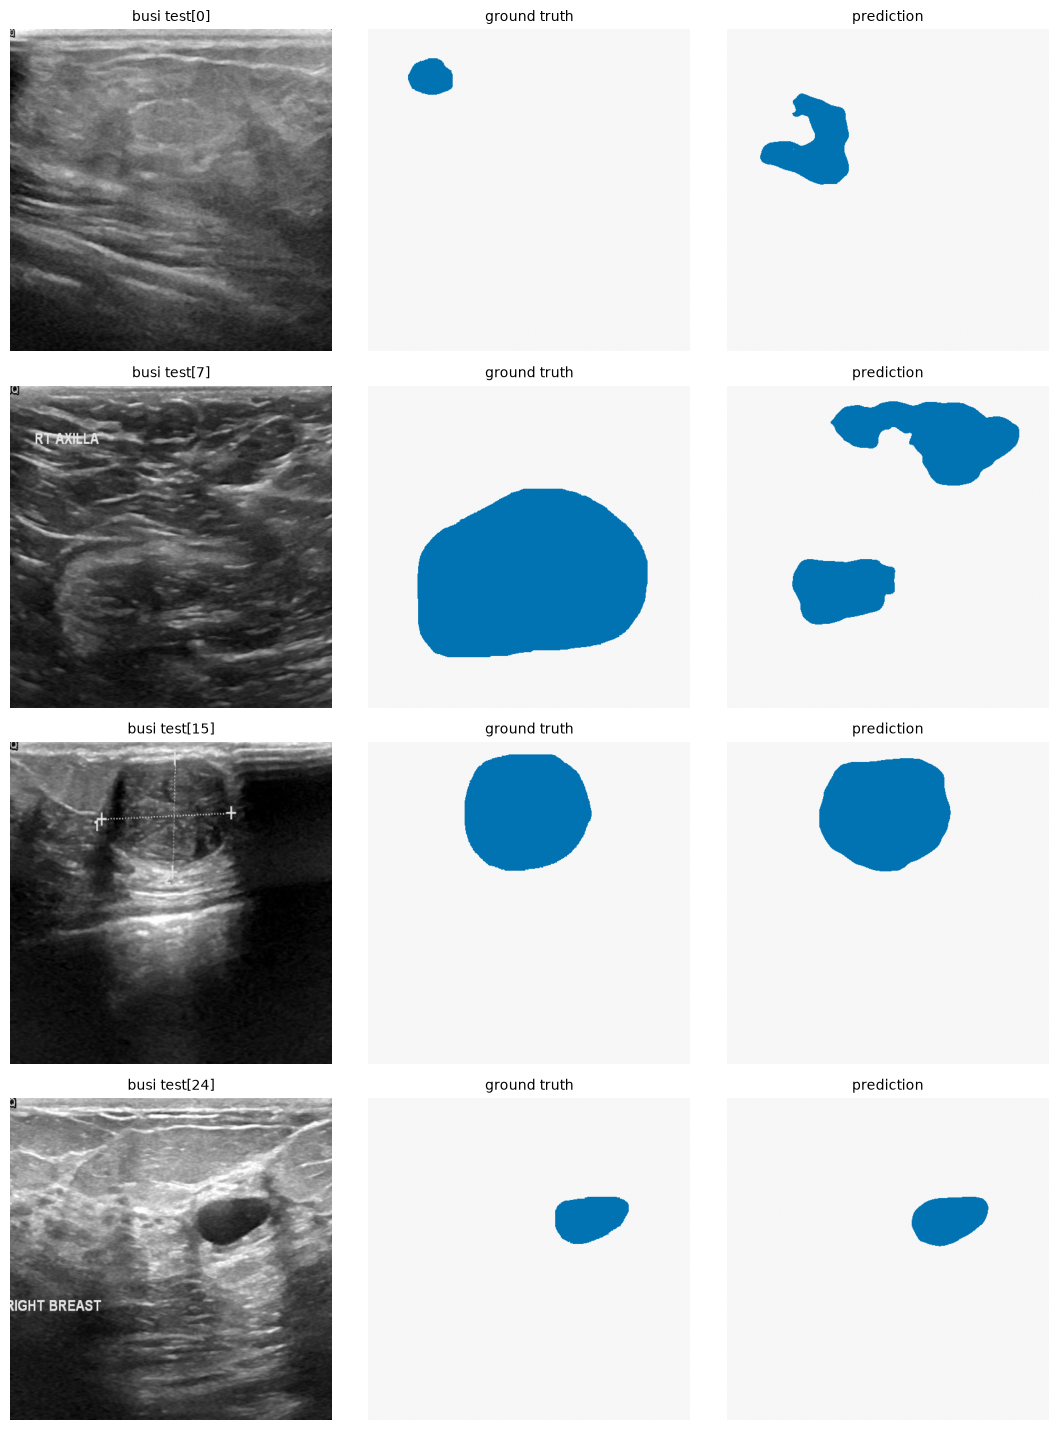

In [7]:
show('busi', indices=(0, 7, 15, 24))

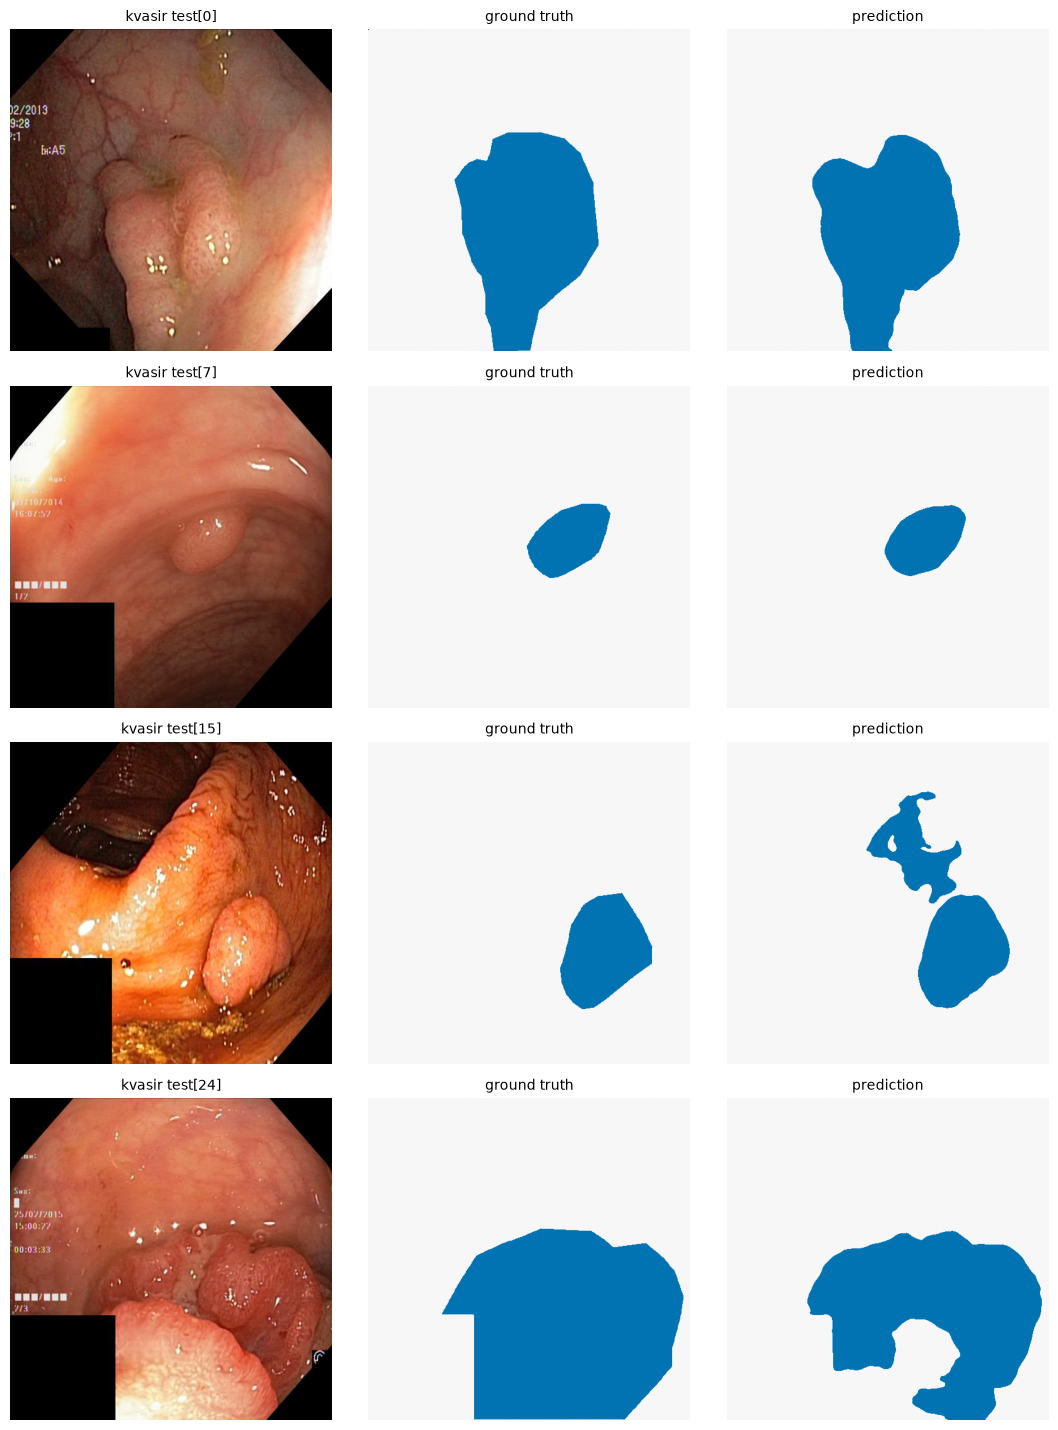

In [8]:
show('kvasir', indices=(0, 7, 15, 24))

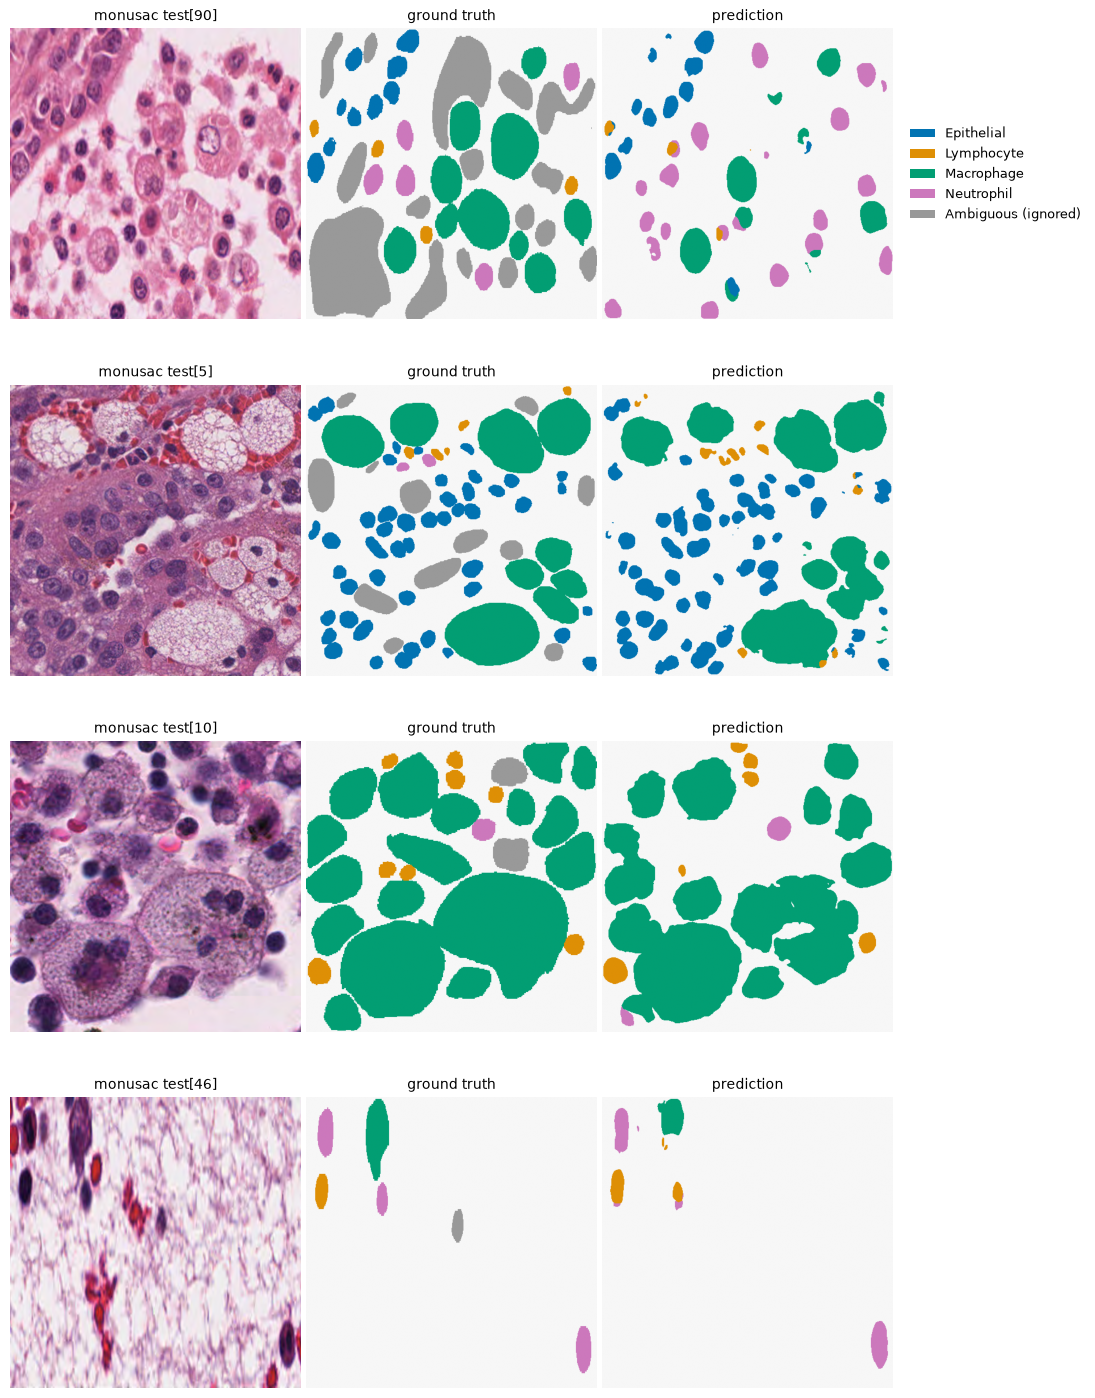

In [9]:
# these indices have multi class 
show('monusac', indices=(90, 5, 10, 46))